In [7]:
import os, torch
print('PyTorch', torch.__version__)
print('GPU:', torch.cuda.get_device_name(0) if torch.cuda.is_available() else 'NOT AVAILABLE -> Runtime > Change runtime type > T4 GPU')

# ---------------- settings ----------------
ZIP_PATH   = '/content/drive/MyDrive/LungLens/archive_1.zip'   # change if your zip is elsewhere
DATA_DIR   = '/content/data'
OUT_DIR    = '/content/outputs'
DRIVE_OUT  = '/content/drive/MyDrive/LungLens/outputs'

QUICK_TEST   = False                 # True = 1+1 epochs, just to test the pipeline
MODELS       = ['densenet121', 'resnet50', 'efficientnet_b0']
EPOCHS_HEAD  = 3                     # stage 1: train only the new classification head
EPOCHS_FT    = 12                    # stage 2: fine-tune the whole network (early stopping, patience 4)
BATCH        = 32
SEED         = 42
BLOCK        = 25                    # block size for the leakage-aware split
PURGE        = 3                     # images dropped next to each block boundary
RUN_RANDOM_SPLIT_COMPARISON = True   # also train once with a naive random split to show the leakage effect
if QUICK_TEST:
    EPOCHS_HEAD, EPOCHS_FT, MODELS = 1, 1, ['densenet121']
os.makedirs(OUT_DIR, exist_ok=True)

PyTorch 2.11.0+cu130
GPU: Tesla T4


In [8]:
from google.colab import drive
drive.mount('/content/drive')
os.makedirs(DATA_DIR, exist_ok=True)
!unzip -oq "$ZIP_PATH" -d "$DATA_DIR"
!ls "$DATA_DIR"

Mounted at /content/drive
'Test cases'  'The IQ-OTHNCCD lung cancer dataset'


In [9]:
%%writefile data_prep.py
import os, re, glob, hashlib
import numpy as np, pandas as pd
from PIL import Image

CLASSES = ['Normal', 'Benign', 'Malignant']
FOLDER2CLASS = {'Normal cases': 'Normal', 'Bengin cases': 'Benign', 'Malignant cases': 'Malignant'}

def find_root(base):
    for dp, dn, _ in os.walk(base):
        if set(FOLDER2CLASS) <= set(dn):
            return dp
    raise FileNotFoundError('Could not find the Normal/Bengin/Malignant folders under ' + base)

def build_dataframe(base):
    root = find_root(base)
    rows = []
    for folder, cls in FOLDER2CLASS.items():
        for p in glob.glob(os.path.join(root, folder, '*')):
            if p.lower().endswith(('.jpg', '.jpeg', '.png')):
                m = re.findall(r'\((\d+)\)', os.path.basename(p))
                with open(p, 'rb') as fh:
                    md5 = hashlib.md5(fh.read()).hexdigest()
                rows.append(dict(path=p, cls=cls, idx=int(m[0]) if m else 0, md5=md5))
    df = pd.DataFrame(rows)
    n0 = len(df)
    # files that appear under two different classes have conflicting labels -> drop all copies
    nun = df.groupby('md5')['cls'].nunique()
    df = df[~df.md5.isin(set(nun[nun > 1].index))]
    # exact duplicates inside a class -> keep the first copy
    df = df.sort_values(['cls', 'idx']).drop_duplicates('md5', keep='first').reset_index(drop=True)
    print(f'Images found: {n0} | after removing duplicates/conflicts: {len(df)} | removed: {n0 - len(df)}')
    return df

def block_split(df, block=25, purge=3, ratios=(0.70, 0.15, 0.15), seed=42, min_blocks=10):
    """Leakage-aware split. Neighbouring file numbers are near-identical CT slices (probably the same patient),
    so contiguous blocks of files are assigned to ONE partition, and `purge` images next to every block
    boundary are dropped from the lower-priority side (priority: test > val > train)."""
    rng = np.random.RandomState(seed)
    out = df.copy(); out['split'] = ''
    prio = {'test': 2, 'val': 1, 'train': 0}
    for cls, g in out.groupby('cls'):
        g = g.sort_values('idx'); ix = g.index.values; n = len(ix)
        nb = max(int(np.ceil(n / block)), min_blocks)          # at least `min_blocks` blocks per class
        order = np.arange(nb); rng.shuffle(order)
        n_test = max(1, int(round(nb * ratios[2]))); n_val = max(1, int(round(nb * ratios[1])))
        block_split_name = {}
        for k, b in enumerate(order):
            block_split_name[b] = 'test' if k < n_test else ('val' if k < n_test + n_val else 'train')
        block_id = np.concatenate([np.full(len(c), b) for b, c in enumerate(np.array_split(np.arange(n), nb))])
        part = np.array([block_split_name[b] for b in block_id], dtype=object)
        drop = np.zeros(n, bool)
        for i in range(n - 1):
            if part[i] != part[i + 1]:
                lo = i if prio[part[i]] < prio[part[i + 1]] else i + 1
                step = -1 if lo == i else 1
                for k in range(purge):
                    j = lo + step * k
                    if 0 <= j < n and part[j] == part[lo]:
                        drop[j] = True
        out.loc[ix, 'split'] = part
        out.loc[ix[drop], 'split'] = 'purged'
    return out[out.split != 'purged'].reset_index(drop=True)

def random_split(df, ratios=(0.70, 0.15, 0.15), seed=42):
    from sklearn.model_selection import train_test_split
    tr, tmp = train_test_split(df, test_size=1 - ratios[0], stratify=df.cls, random_state=seed)
    va, te = train_test_split(tmp, test_size=ratios[2] / (ratios[1] + ratios[2]), stratify=tmp.cls, random_state=seed)
    out = df.copy(); out['split'] = ''
    out.loc[tr.index, 'split'] = 'train'; out.loc[va.index, 'split'] = 'val'; out.loc[te.index, 'split'] = 'test'
    return out

def _thumb(p):
    return np.asarray(Image.open(p).convert('L').resize((32, 32)), dtype=np.float32).ravel()

def leakage_score(split_df, cache={}):
    """Mean over test images of the highest correlation with any TRAIN image (32x32 thumbnails).
    Near 1.0 = the test set contains almost-copies of training images."""
    for p in split_df.path:
        if p not in cache: cache[p] = _thumb(p)
    def z(v): v = v - v.mean(); return v / (np.linalg.norm(v) + 1e-9)
    tr = np.stack([z(cache[p]) for p in split_df[split_df.split == 'train'].path])
    te = np.stack([z(cache[p]) for p in split_df[split_df.split == 'test'].path])
    return float((te @ tr.T).max(1).mean())

Writing data_prep.py


In [10]:
%%writefile ct_core.py
"""LungLens - shared deep-learning code (used by the Colab notebook AND the Flask app).
Needs: torch, torchvision."""
import torch
import torch.nn as nn
import torch.nn.functional as F
from torchvision import models

ARCHS = ('densenet121', 'resnet50', 'efficientnet_b0')
IMG_SIZE = 224
MEAN = [0.485, 0.456, 0.406]
STD = [0.229, 0.224, 0.225]


def build_model(arch, num_classes=3, pretrained=True):
    """ImageNet-pretrained backbone with a new classification head."""
    if arch == 'densenet121':
        m = models.densenet121(weights=models.DenseNet121_Weights.DEFAULT if pretrained else None)
        m.classifier = nn.Linear(m.classifier.in_features, num_classes)
    elif arch == 'resnet50':
        m = models.resnet50(weights=models.ResNet50_Weights.DEFAULT if pretrained else None)
        m.fc = nn.Linear(m.fc.in_features, num_classes)
    elif arch == 'efficientnet_b0':
        m = models.efficientnet_b0(weights=models.EfficientNet_B0_Weights.DEFAULT if pretrained else None)
        m.classifier[1] = nn.Linear(m.classifier[1].in_features, num_classes)
    else:
        raise ValueError('Unknown architecture: ' + str(arch))
    return m


def head_parameters(model, arch):
    head = model.fc if arch == 'resnet50' else model.classifier
    return list(head.parameters())


def split_forward(model, arch):
    """Return (feature_fn, head_fn): the network split at its last convolutional feature map,
    which is where Grad-CAM needs the gradients."""
    if arch == 'densenet121':
        feat = lambda x: model.features(x)
        head = lambda f: model.classifier(torch.flatten(F.adaptive_avg_pool2d(F.relu(f), (1, 1)), 1))
    elif arch == 'resnet50':
        def feat(x):
            x = model.maxpool(model.relu(model.bn1(model.conv1(x))))
            return model.layer4(model.layer3(model.layer2(model.layer1(x))))
        head = lambda f: model.fc(torch.flatten(model.avgpool(f), 1))
    elif arch == 'efficientnet_b0':
        feat = lambda x: model.features(x)
        head = lambda f: model.classifier(torch.flatten(model.avgpool(f), 1))
    else:
        raise ValueError('Unknown architecture: ' + str(arch))
    return feat, head


def grad_cam(model, arch, x, class_idx=None):
    """Grad-CAM for one image tensor x of shape [1,3,H,W].
    Returns (cam in [0,1] as a 2-D numpy array, class probabilities, class index explained)."""
    model.eval()
    feat_fn, head_fn = split_forward(model, arch)
    with torch.enable_grad():
        f = feat_fn(x)
        logits = head_fn(f)
        probs = torch.softmax(logits, dim=1)[0].detach()
        if class_idx is None:
            class_idx = int(probs.argmax())
        grads = torch.autograd.grad(logits[0, class_idx], f)[0]
        weights = grads.mean(dim=(2, 3), keepdim=True)
        cam = F.relu((weights * f).sum(dim=1))[0].detach()
    cam = cam - cam.min()
    cam = cam / (cam.max() + 1e-8)
    return cam.cpu().numpy(), probs.cpu().numpy(), class_idx

Writing ct_core.py


Images found: 1097 | after removing duplicates/conflicts: 1054 | removed: 43

Leakage-aware (block-wise) split:


cls,Normal,Benign,Malignant
split,,,
train,238,45,368
val,69,18,75
test,71,21,74


Images purged at block boundaries: 75
Leakage score  random split: 0.989   block-wise split: 0.895


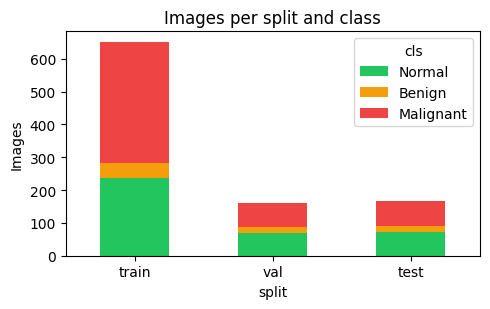

In [11]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt, json, random, time, copy
from data_prep import *
import ct_core

def set_seed(s):
    random.seed(s); np.random.seed(s); torch.manual_seed(s); torch.cuda.manual_seed_all(s)
set_seed(SEED)

df = build_dataframe(DATA_DIR)
split_df = block_split(df, block=BLOCK, purge=PURGE, seed=SEED)
split_counts = split_df.groupby(['split', 'cls']).size().unstack(fill_value=0).reindex(['train', 'val', 'test'])[CLASSES]
print('\nLeakage-aware (block-wise) split:'); display(split_counts)
print('Images purged at block boundaries:', len(df) - len(split_df))

leak_block  = leakage_score(split_df)
leak_random = leakage_score(random_split(df, seed=SEED))
print(f'Leakage score  random split: {leak_random:.3f}   block-wise split: {leak_block:.3f}')

ax = split_counts.plot(kind='bar', stacked=True, figsize=(5, 3.2), color=['#22c55e', '#f59e0b', '#ef4444'])
ax.set_ylabel('Images'); ax.set_title('Images per split and class'); plt.xticks(rotation=0); plt.tight_layout()
plt.savefig(f'{OUT_DIR}/fig_split_distribution.png', dpi=200); plt.show()

In [12]:
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms as T
from PIL import Image

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
use_amp = device.type == 'cuda'
CLASS_TO_IDX = {c: i for i, c in enumerate(CLASSES)}
norm = T.Normalize(ct_core.MEAN, ct_core.STD)
train_tf = T.Compose([T.Resize((224, 224)),
                      T.RandomAffine(degrees=10, translate=(0.05, 0.05), scale=(0.9, 1.1)),
                      T.ColorJitter(brightness=0.15, contrast=0.15),
                      T.ToTensor(), norm])
eval_tf = T.Compose([T.Resize((224, 224)), T.ToTensor(), norm])     # identical to the preprocessing in the web app

class CTDataset(Dataset):
    def __init__(self, d, tf):
        self.p = d.path.tolist(); self.y = [CLASS_TO_IDX[c] for c in d.cls]; self.tf = tf
    def __len__(self): return len(self.p)
    def __getitem__(self, i): return self.tf(Image.open(self.p[i]).convert('RGB')), self.y[i]

def make_loaders(sdf):
    parts = {k: sdf[sdf.split == k] for k in ['train', 'val', 'test']}
    g = torch.Generator(); g.manual_seed(SEED)
    loaders = {'train': DataLoader(CTDataset(parts['train'], train_tf), batch_size=BATCH, shuffle=True, num_workers=2, generator=g, drop_last=True),
               'val':   DataLoader(CTDataset(parts['val'], eval_tf), batch_size=BATCH, shuffle=False, num_workers=2),
               'test':  DataLoader(CTDataset(parts['test'], eval_tf), batch_size=BATCH, shuffle=False, num_workers=2)}
    return loaders, parts

def weights_from(parts):
    counts = parts['train'].cls.value_counts().reindex(CLASSES).values
    return torch.tensor(counts.sum() / (len(CLASSES) * counts), dtype=torch.float32)   # inverse-frequency class weights

loaders, parts = make_loaders(split_df)
class_weights = weights_from(parts)
print('Class weights (Normal, Benign, Malignant):', class_weights.numpy().round(2))

Class weights (Normal, Benign, Malignant): [0.91 4.82 0.59]


In [13]:
import torch.nn as nn
from sklearn.metrics import accuracy_score, precision_recall_fscore_support, confusion_matrix, roc_auc_score, roc_curve

def run_epoch(model, loader, criterion, optimizer=None, scaler=None):
    train = optimizer is not None
    model.train(train)
    total, n = 0.0, 0
    for x, y in loader:
        x, y = x.to(device, non_blocking=True), y.to(device, non_blocking=True)
        with torch.set_grad_enabled(train):
            with torch.autocast(device_type=device.type, enabled=use_amp):
                out = model(x); loss = criterion(out, y)
        if train:
            optimizer.zero_grad(set_to_none=True)
            scaler.scale(loss).backward(); scaler.step(optimizer); scaler.update()
        total += loss.item() * len(y); n += len(y)
    return total / n

@torch.no_grad()
def predict_probs(model, loader):
    model.eval(); P, Y = [], []
    for x, y in loader:
        with torch.autocast(device_type=device.type, enabled=use_amp):
            out = model(x.to(device))
        P.append(torch.softmax(out.float(), 1).cpu().numpy()); Y.append(y.numpy())
    return np.concatenate(Y), np.concatenate(P)

def compute_metrics(y, P):
    pred = P.argmax(1); C = len(CLASSES); labels = list(range(C))
    cm = confusion_matrix(y, pred, labels=labels)
    pr, rc, f1, _ = precision_recall_fscore_support(y, pred, labels=labels, average='macro', zero_division=0)
    m = {'accuracy': accuracy_score(y, pred), 'macro_precision': pr, 'macro_recall': rc, 'macro_f1': f1}
    tot = cm.sum()
    for i, c in enumerate(CLASSES):
        tp = cm[i, i]; fn = cm[i].sum() - tp; fp = cm[:, i].sum() - tp; tn = tot - tp - fn - fp
        m[f'sens_{c}'] = tp / (tp + fn) if tp + fn else float('nan')
        m[f'spec_{c}'] = tn / (tn + fp) if tn + fp else float('nan')
    try: m['macro_auc'] = roc_auc_score(y, P, multi_class='ovr', average='macro', labels=labels)
    except ValueError: m['macro_auc'] = float('nan')
    return {k: float(v) for k, v in m.items()}, cm

def new_scaler():
    return torch.amp.GradScaler('cuda', enabled=use_amp) if hasattr(torch.amp, 'GradScaler') else torch.cuda.amp.GradScaler(enabled=use_amp)

def fit(arch, loaders, class_weights, epochs_head, epochs_ft, patience=4):
    set_seed(SEED)
    model = ct_core.build_model(arch, num_classes=len(CLASSES), pretrained=True).to(device)
    criterion = nn.CrossEntropyLoss(weight=class_weights.to(device))
    hist, best_f1, best_state = [], -1.0, None

    def evaluate(stage, ep, tr_loss):
        nonlocal best_f1, best_state
        vl = run_epoch(model, loaders['val'], criterion)
        y, P = predict_probs(model, loaders['val']); m, _ = compute_metrics(y, P)
        hist.append({'stage': stage, 'epoch': len(hist) + 1, 'train_loss': tr_loss, 'val_loss': vl, 'val_acc': m['accuracy'], 'val_f1': m['macro_f1']})
        print(f"  [{stage}] epoch {len(hist):2d}  train loss {tr_loss:.3f}  val loss {vl:.3f}  val acc {m['accuracy']:.3f}  val macro-F1 {m['macro_f1']:.3f}")
        if m['macro_f1'] > best_f1:
            best_f1 = m['macro_f1']; best_state = {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}
            return True
        return False

    # stage 1: new head only
    for p in model.parameters(): p.requires_grad = False
    head = ct_core.head_parameters(model, arch)
    for p in head: p.requires_grad = True
    opt = torch.optim.AdamW(head, lr=1e-3, weight_decay=1e-4); sc = new_scaler()
    for ep in range(epochs_head):
        evaluate('head', ep, run_epoch(model, loaders['train'], criterion, opt, sc))
    # stage 2: fine-tune everything
    for p in model.parameters(): p.requires_grad = True
    opt = torch.optim.AdamW(model.parameters(), lr=1e-4, weight_decay=1e-4); sc = new_scaler()
    sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=max(epochs_ft, 1)); bad = 0
    for ep in range(epochs_ft):
        tl = run_epoch(model, loaders['train'], criterion, opt, sc); sched.step()
        bad = 0 if evaluate('finetune', ep, tl) else bad + 1
        if bad >= patience:
            print('  early stopping'); break
    model.load_state_dict(best_state)
    return model, pd.DataFrame(hist), best_f1

In [14]:
results, histories, cms, test_probs = {}, {}, {}, {}
for arch in MODELS:
    print(f'\n=== {arch} ===')
    t0 = time.time()
    model, hist, best_val = fit(arch, loaders, class_weights, EPOCHS_HEAD, EPOCHS_FT)
    y, P = predict_probs(model, loaders['test']); m, cm = compute_metrics(y, P)
    results[arch] = {'val_macro_f1': float(best_val), **m, 'train_minutes': (time.time() - t0) / 60}
    histories[arch], cms[arch], test_probs[arch] = hist, cm, (y, P)
    torch.save({'arch': arch, 'classes': CLASSES, 'state_dict': {k: v.cpu() for k, v in model.state_dict().items()}}, f'{OUT_DIR}/ckpt_{arch}.pt')
    print(f"  TEST  accuracy {m['accuracy']:.3f} | macro-F1 {m['macro_f1']:.3f} | macro-AUC {m['macro_auc']:.3f} | sensitivity(Malignant) {m['sens_Malignant']:.3f}")
    del model; torch.cuda.empty_cache()


=== densenet121 ===
Downloading: "https://download.pytorch.org/models/densenet121-a639ec97.pth" to /root/.cache/torch/hub/checkpoints/densenet121-a639ec97.pth


100%|██████████| 30.8M/30.8M [00:00<00:00, 160MB/s]


  [head] epoch  1  train loss 1.022  val loss 0.864  val acc 0.667  val macro-F1 0.572
  [head] epoch  2  train loss 0.782  val loss 0.697  val acc 0.840  val macro-F1 0.708
  [head] epoch  3  train loss 0.674  val loss 0.737  val acc 0.599  val macro-F1 0.572
  [finetune] epoch  4  train loss 0.506  val loss 0.795  val acc 0.673  val macro-F1 0.598
  [finetune] epoch  5  train loss 0.234  val loss 0.344  val acc 0.889  val macro-F1 0.806
  [finetune] epoch  6  train loss 0.183  val loss 0.364  val acc 0.864  val macro-F1 0.669
  [finetune] epoch  7  train loss 0.127  val loss 0.486  val acc 0.772  val macro-F1 0.706
  [finetune] epoch  8  train loss 0.060  val loss 0.335  val acc 0.926  val macro-F1 0.879
  [finetune] epoch  9  train loss 0.045  val loss 0.376  val acc 0.889  val macro-F1 0.805
  [finetune] epoch 10  train loss 0.052  val loss 0.373  val acc 0.920  val macro-F1 0.866
  [finetune] epoch 11  train loss 0.034  val loss 0.385  val acc 0.907  val macro-F1 0.821
  [finetune

100%|██████████| 97.8M/97.8M [00:00<00:00, 175MB/s]


  [head] epoch  1  train loss 0.980  val loss 0.908  val acc 0.735  val macro-F1 0.513
  [head] epoch  2  train loss 0.795  val loss 0.780  val acc 0.815  val macro-F1 0.583
  [head] epoch  3  train loss 0.679  val loss 0.642  val acc 0.846  val macro-F1 0.634
  [finetune] epoch  4  train loss 0.538  val loss 0.418  val acc 0.833  val macro-F1 0.704
  [finetune] epoch  5  train loss 0.324  val loss 0.347  val acc 0.858  val macro-F1 0.766
  [finetune] epoch  6  train loss 0.238  val loss 0.361  val acc 0.852  val macro-F1 0.781
  [finetune] epoch  7  train loss 0.166  val loss 0.336  val acc 0.914  val macro-F1 0.854
  [finetune] epoch  8  train loss 0.089  val loss 0.354  val acc 0.889  val macro-F1 0.781
  [finetune] epoch  9  train loss 0.050  val loss 0.346  val acc 0.901  val macro-F1 0.820
  [finetune] epoch 10  train loss 0.060  val loss 0.358  val acc 0.895  val macro-F1 0.825
  [finetune] epoch 11  train loss 0.054  val loss 0.502  val acc 0.821  val macro-F1 0.748
  early sto

100%|██████████| 20.5M/20.5M [00:00<00:00, 133MB/s]


  [head] epoch  1  train loss 0.882  val loss 0.846  val acc 0.630  val macro-F1 0.524
  [head] epoch  2  train loss 0.633  val loss 0.848  val acc 0.617  val macro-F1 0.515
  [head] epoch  3  train loss 0.526  val loss 0.673  val acc 0.704  val macro-F1 0.626
  [finetune] epoch  4  train loss 0.481  val loss 0.470  val acc 0.772  val macro-F1 0.701
  [finetune] epoch  5  train loss 0.316  val loss 0.490  val acc 0.765  val macro-F1 0.700
  [finetune] epoch  6  train loss 0.245  val loss 0.504  val acc 0.741  val macro-F1 0.673
  [finetune] epoch  7  train loss 0.195  val loss 0.341  val acc 0.852  val macro-F1 0.781
  [finetune] epoch  8  train loss 0.191  val loss 0.535  val acc 0.765  val macro-F1 0.700
  [finetune] epoch  9  train loss 0.172  val loss 0.481  val acc 0.809  val macro-F1 0.743
  [finetune] epoch 10  train loss 0.121  val loss 0.564  val acc 0.784  val macro-F1 0.717
  [finetune] epoch 11  train loss 0.097  val loss 0.492  val acc 0.815  val macro-F1 0.746
  early sto

In [15]:
names = {'densenet121': 'DenseNet121', 'resnet50': 'ResNet50', 'efficientnet_b0': 'EfficientNet-B0'}
rows = []
for a, r in results.items():
    rows.append({'Model': names[a], 'Accuracy': r['accuracy'], 'Macro-Precision': r['macro_precision'], 'Macro-Recall': r['macro_recall'],
                 'Macro-F1': r['macro_f1'], 'Macro-AUC': r['macro_auc'],
                 'Sens. Normal': r['sens_Normal'], 'Sens. Benign': r['sens_Benign'], 'Sens. Malignant': r['sens_Malignant'],
                 'Spec. Malignant': r['spec_Malignant'], 'Val macro-F1': r['val_macro_f1']})
comparison = pd.DataFrame(rows).set_index('Model')
comparison.round(3).to_csv(f'{OUT_DIR}/comparison_table.csv')
print('TEST-SET RESULTS (leakage-aware block-wise split)'); display(comparison.round(3))

# the model to deploy is chosen on VALIDATION macro-F1 (never on the test set)
DEPLOY_ARCH = max(results, key=lambda a: results[a]['val_macro_f1'])
print('Model selected for deployment (best validation macro-F1):', names[DEPLOY_ARCH])

TEST-SET RESULTS (leakage-aware block-wise split)


,Accuracy,Macro-Precision,Macro-Recall,Macro-F1,Macro-AUC,Sens. Normal,Sens. Benign,Sens. Malignant,Spec. Malignant,Val macro-F1
Model,,,,,,,,,,
DenseNet121,0.705,0.609,0.593,0.597,0.747,0.704,0.238,0.838,0.935,0.879
ResNet50,0.711,0.652,0.644,0.637,0.756,0.761,0.429,0.743,0.989,0.854
EfficientNet-B0,0.675,0.633,0.626,0.608,0.760,0.563,0.476,0.838,0.957,0.781


Model selected for deployment (best validation macro-F1): DenseNet121


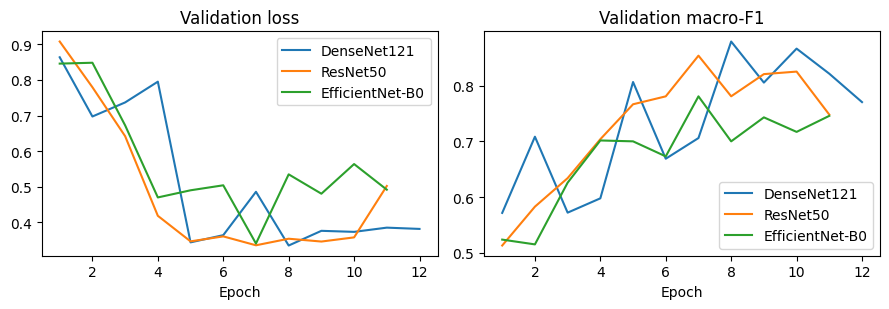

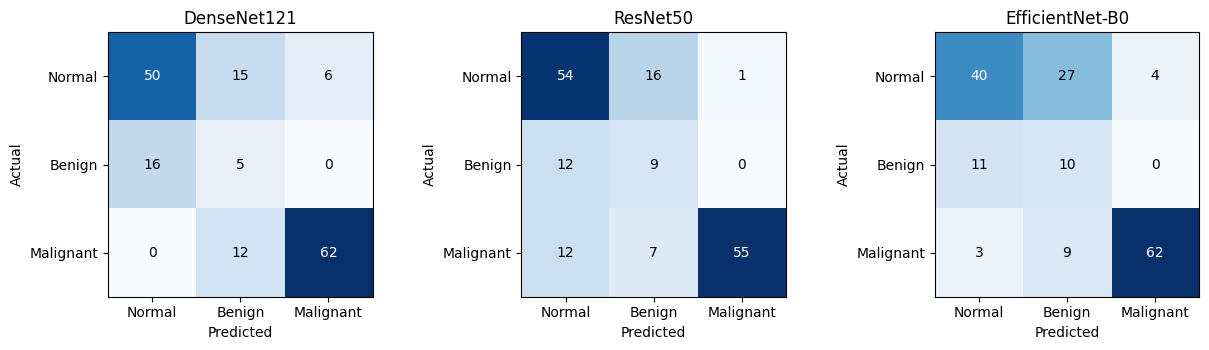

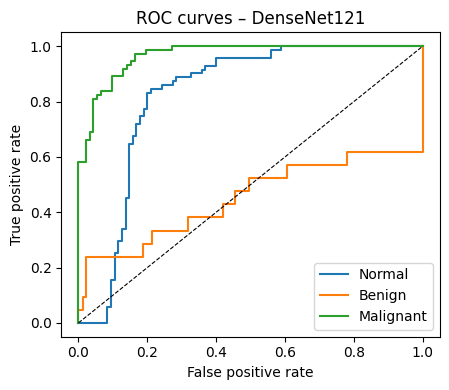

In [16]:
# training curves
fig, axs = plt.subplots(1, 2, figsize=(9, 3.2))
for a, h in histories.items():
    axs[0].plot(h.epoch, h.val_loss, label=names[a]); axs[1].plot(h.epoch, h.val_f1, label=names[a])
axs[0].set_title('Validation loss'); axs[1].set_title('Validation macro-F1')
for ax in axs: ax.set_xlabel('Epoch'); ax.legend()
plt.tight_layout(); plt.savefig(f'{OUT_DIR}/fig_training_curves.png', dpi=200); plt.show()

# confusion matrices on the test set
fig, axs = plt.subplots(1, len(cms), figsize=(4.2 * len(cms), 3.6), squeeze=False)
for ax, (a, cm) in zip(axs[0], cms.items()):
    ax.imshow(cm, cmap='Blues'); ax.set_title(names[a])
    for i in range(3):
        for j in range(3):
            ax.text(j, i, int(cm[i, j]), ha='center', va='center', color='white' if cm[i, j] > cm.max() / 2 else 'black')
    ax.set_xticks(range(3)); ax.set_yticks(range(3)); ax.set_xticklabels(CLASSES); ax.set_yticklabels(CLASSES)
    ax.set_xlabel('Predicted'); ax.set_ylabel('Actual')
plt.tight_layout(); plt.savefig(f'{OUT_DIR}/fig_confusion_matrices.png', dpi=200); plt.show()

# one-vs-rest ROC curves of the deployed model
y, P = test_probs[DEPLOY_ARCH]
plt.figure(figsize=(4.6, 4))
for i, c in enumerate(CLASSES):
    if (y == i).any():
        fpr, tpr, _ = roc_curve((y == i).astype(int), P[:, i]); plt.plot(fpr, tpr, label=c)
plt.plot([0, 1], [0, 1], 'k--', lw=0.8); plt.xlabel('False positive rate'); plt.ylabel('True positive rate')
plt.title(f'ROC curves – {names[DEPLOY_ARCH]}'); plt.legend(); plt.tight_layout()
plt.savefig(f'{OUT_DIR}/fig_roc.png', dpi=200); plt.show()

## 5. Grad-CAM: what does the model look at?
Coloured regions (red = strongest) show where the model found evidence for its prediction. Check that they lie inside the lungs; if they point at the table, the text or the image border, the model is using shortcuts.

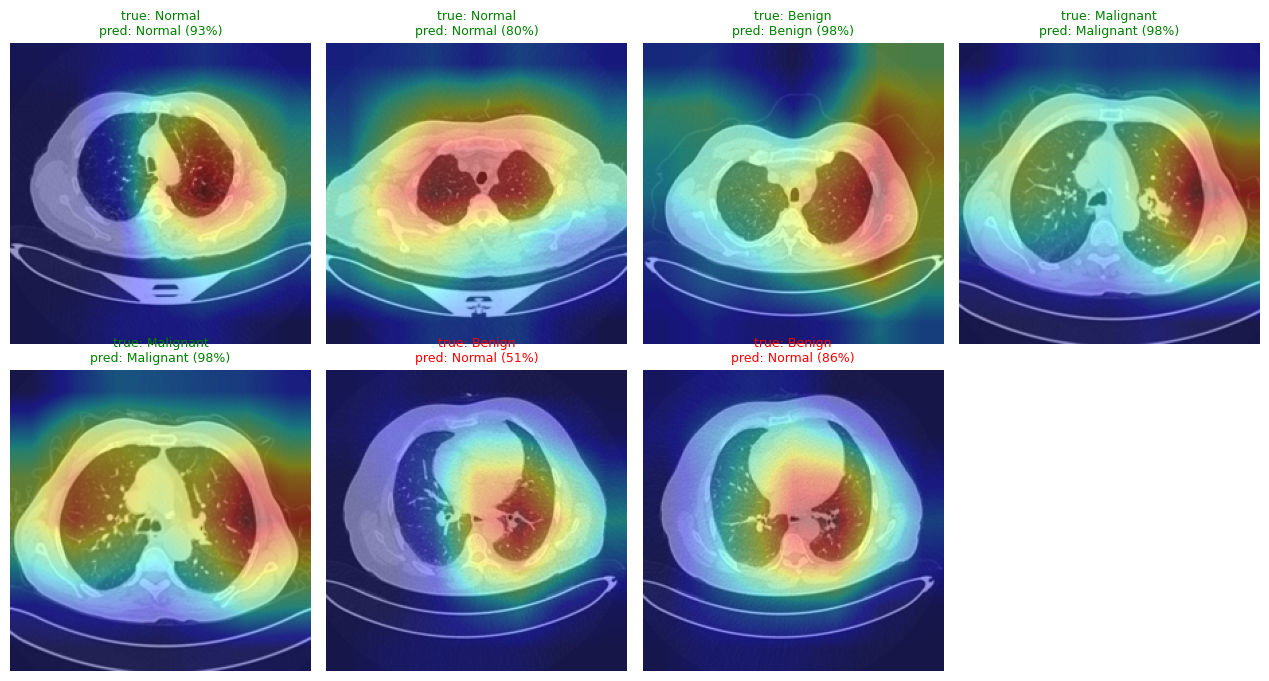

In [17]:
import torch.nn.functional as F
ck = torch.load(f'{OUT_DIR}/ckpt_{DEPLOY_ARCH}.pt', map_location='cpu', weights_only=True)
gmodel = ct_core.build_model(DEPLOY_ARCH, num_classes=len(CLASSES), pretrained=False)
gmodel.load_state_dict(ck['state_dict']); gmodel.to(device).eval()

test_df = parts['test'].reset_index(drop=True)
y_true, P = test_probs[DEPLOY_ARCH]; y_pred = P.argmax(1)
picked = []
for c in range(len(CLASSES)):                                   # up to 2 correct examples per class
    picked += [i for i in np.where((y_true == c) & (y_pred == c))[0][::7][:2]]
picked += list(np.where(y_true != y_pred)[0][:2])                # and up to 2 mistakes
cols = 4; rows_n = int(np.ceil(len(picked) / cols))
fig, axs = plt.subplots(rows_n, cols, figsize=(3.2 * cols, 3.4 * rows_n), squeeze=False)
for ax in axs.ravel(): ax.axis('off')
for ax, i in zip(axs.ravel(), picked):
    img = Image.open(test_df.path[i]).convert('RGB').resize((224, 224))
    x = eval_tf(Image.open(test_df.path[i]).convert('RGB')).unsqueeze(0).to(device)
    cam, probs, idx = ct_core.grad_cam(gmodel, DEPLOY_ARCH, x)
    cam224 = F.interpolate(torch.tensor(cam)[None, None], size=(224, 224), mode='bilinear', align_corners=False)[0, 0].numpy()
    ax.imshow(img); ax.imshow(cam224, cmap='jet', alpha=0.4)
    ax.set_title(f'true: {CLASSES[y_true[i]]}\npred: {CLASSES[idx]} ({probs[idx]*100:.0f}%)', fontsize=9, color='green' if idx == y_true[i] else 'red')
plt.tight_layout(); plt.savefig(f'{OUT_DIR}/fig_gradcam.png', dpi=200); plt.show()

## 6. How much does a naive random split inflate the result?
The same model is trained again with an ordinary random image-level split. If its test score is clearly higher than the block-wise one, part of that score is memorisation of near-identical slices. This table is evidence for the paper.

In [18]:
split_comparison = None
if RUN_RANDOM_SPLIT_COMPARISON:
    rdf = random_split(df, seed=SEED)
    r_loaders, r_parts = make_loaders(rdf)
    print('Random image-level split, model:', names[DEPLOY_ARCH])
    rmodel, _, _ = fit(DEPLOY_ARCH, r_loaders, weights_from(r_parts), EPOCHS_HEAD, EPOCHS_FT)
    y, P = predict_probs(rmodel, r_loaders['test']); rm, _ = compute_metrics(y, P)
    bm = results[DEPLOY_ARCH]
    split_comparison = pd.DataFrame({
        'Block-wise split (leakage-aware)': [bm['accuracy'], bm['macro_f1'], bm['macro_auc'], bm['sens_Malignant'], leak_block],
        'Random image-level split':         [rm['accuracy'], rm['macro_f1'], rm['macro_auc'], rm['sens_Malignant'], leak_random]},
        index=['Accuracy', 'Macro-F1', 'Macro-AUC', 'Sensitivity (Malignant)', 'Leakage score']).round(3)
    split_comparison.to_csv(f'{OUT_DIR}/split_comparison.csv'); display(split_comparison)
    del rmodel; torch.cuda.empty_cache()

Random image-level split, model: DenseNet121
  [head] epoch  1  train loss 1.024  val loss 0.839  val acc 0.658  val macro-F1 0.518
  [head] epoch  2  train loss 0.796  val loss 0.801  val acc 0.570  val macro-F1 0.536
  [head] epoch  3  train loss 0.729  val loss 0.632  val acc 0.848  val macro-F1 0.694
  [finetune] epoch  4  train loss 0.515  val loss 0.455  val acc 0.816  val macro-F1 0.710
  [finetune] epoch  5  train loss 0.342  val loss 0.288  val acc 0.930  val macro-F1 0.844
  [finetune] epoch  6  train loss 0.215  val loss 0.161  val acc 0.943  val macro-F1 0.895
  [finetune] epoch  7  train loss 0.143  val loss 0.145  val acc 0.949  val macro-F1 0.868
  [finetune] epoch  8  train loss 0.116  val loss 0.202  val acc 0.943  val macro-F1 0.846
  [finetune] epoch  9  train loss 0.073  val loss 0.130  val acc 0.962  val macro-F1 0.921
  [finetune] epoch 10  train loss 0.058  val loss 0.089  val acc 0.975  val macro-F1 0.942
  [finetune] epoch 11  train loss 0.041  val loss 0.081  

,Block-wise split (leakage-aware),Random image-level split
Accuracy,0.705,0.975
Macro-F1,0.597,0.952
Macro-AUC,0.747,0.999
Sensitivity (Malignant),0.838,1.000
Leakage score,0.895,0.989


In [19]:
ckpt = torch.load(f'{OUT_DIR}/ckpt_{DEPLOY_ARCH}.pt', map_location='cpu', weights_only=True)
ckpt['img_size'] = 224
ckpt['metrics'] = {k: float(v) for k, v in results[DEPLOY_ARCH].items()}
torch.save(ckpt, f'{OUT_DIR}/ct_model.pt')

summary = {
    'dataset': {'images_after_dedup': int(len(df)), 'split_counts': split_counts.to_dict(), 'purged': int(len(df) - len(split_df)),
                'leakage_score_block': leak_block, 'leakage_score_random': leak_random},
    'settings': {'seed': SEED, 'block': BLOCK, 'purge': PURGE, 'epochs_head': EPOCHS_HEAD, 'epochs_finetune': EPOCHS_FT, 'batch': BATCH, 'quick_test': QUICK_TEST},
    'results': results, 'deployed_model': DEPLOY_ARCH,
    'split_comparison': split_comparison.to_dict() if split_comparison is not None else None}
json.dump(summary, open(f'{OUT_DIR}/results.json', 'w'), indent=2, default=float)
for a in MODELS: os.remove(f'{OUT_DIR}/ckpt_{a}.pt')          # only ct_model.pt is needed
!cd /content && zip -qr LungLens_results.zip outputs
os.makedirs(DRIVE_OUT, exist_ok=True)
!cp -r {OUT_DIR}/* "{DRIVE_OUT}/"
print('Saved to Drive:', DRIVE_OUT)
print(os.listdir(OUT_DIR))
from google.colab import files
files.download(f'{OUT_DIR}/ct_model.pt'); files.download('/content/LungLens_results.zip')

Saved to Drive: /content/drive/MyDrive/LungLens/outputs
['results.json', 'fig_roc.png', 'fig_training_curves.png', 'fig_split_distribution.png', 'comparison_table.csv', 'fig_gradcam.png', 'split_comparison.csv', 'ct_model.pt', 'fig_confusion_matrices.png']


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>